<a href="https://colab.research.google.com/github/jumailtaj/House-price-predictor/blob/main/House_Price_Predictor(banglore).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import joblib


In [ ]:

data_url = "https://raw.githubusercontent.com/dphi-official/Datasets/master/Bengaluru_House_Data.csv"

try:
    df = pd.read_csv(data_url)
    print("Dataset downloaded successfully!")
except Exception as error:
    print("Dataset download failed:", error)
    print("Upload your Bengaluru house-price CSV file.")
    from google.colab import files
    uploaded = files.upload()
    file_name = list(uploaded.keys())[0]
    df = pd.read_csv(file_name)

print(df.head())
print("Dataset shape:", df.shape)


Dataset downloaded successfully!
              area_type   availability                  location       size  \
0  Super built-up  Area         19-Dec  Electronic City Phase II      2 BHK   
1            Plot  Area  Ready To Move          Chikka Tirupathi  4 Bedroom   
2        Built-up  Area  Ready To Move               Uttarahalli      3 BHK   
3  Super built-up  Area  Ready To Move        Lingadheeranahalli      3 BHK   
4  Super built-up  Area  Ready To Move                  Kothanur      2 BHK   

   society total_sqft  bath  balcony   price  
0  Coomee        1056   2.0      1.0   39.07  
1  Theanmp       2600   5.0      3.0  120.00  
2      NaN       1440   2.0      3.0   62.00  
3  Soiewre       1521   3.0      1.0   95.00  
4      NaN       1200   2.0      1.0   51.00  
Dataset shape: (13320, 9)


In [ ]:


print(df.info())
print(df.isnull().sum())
print(df.describe())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB
None
area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64
               bath       balcony         price
count  13247.000000  12711.000000  13320.000000
mean       2.692610      1.584376    112.565627
std        1.3

In [ ]:


house = df.copy()
house = house.drop(columns=["society", "availability"], errors="ignore")


In [ ]:


def convert_sqft(value):
    try:
        value = str(value)

        if "-" in value:
            parts = value.split("-")
            first = float(parts[0])
            second = float(parts[1])
            return (first + second) / 2

        return float(value)

    except:
        return np.nan


house["total_sqft"] = house["total_sqft"].apply(convert_sqft)
house["bhk"] = house["size"].str.extract(r"(\d+)").astype(float)
house["bath"] = pd.to_numeric(house["bath"], errors="coerce")
house["balcony"] = pd.to_numeric(house["balcony"], errors="coerce")

house = house.drop(columns=["size"], errors="ignore")


In [ ]:


house = house[
    (house["total_sqft"] > 0) &
    (house["price"] > 0) &
    (house["bhk"] > 0)
].copy()

house["sqft_per_bhk"] = house["total_sqft"] / house["bhk"]

house = house[
    (house["sqft_per_bhk"] >= 200) &
    (house["sqft_per_bhk"] <= 2000)
].copy()

house = house.drop(columns=["sqft_per_bhk"])
house = house.reset_index(drop=True)

print("Rows after cleaning:", len(house))
print(house.head())


Rows after cleaning: 12882
              area_type                  location  total_sqft  bath  balcony  \
0  Super built-up  Area  Electronic City Phase II      1056.0   2.0      1.0   
1            Plot  Area          Chikka Tirupathi      2600.0   5.0      3.0   
2        Built-up  Area               Uttarahalli      1440.0   2.0      3.0   
3  Super built-up  Area        Lingadheeranahalli      1521.0   3.0      1.0   
4  Super built-up  Area                  Kothanur      1200.0   2.0      1.0   

    price  bhk  
0   39.07  2.0  
1  120.00  4.0  
2   62.00  3.0  
3   95.00  3.0  
4   51.00  2.0  


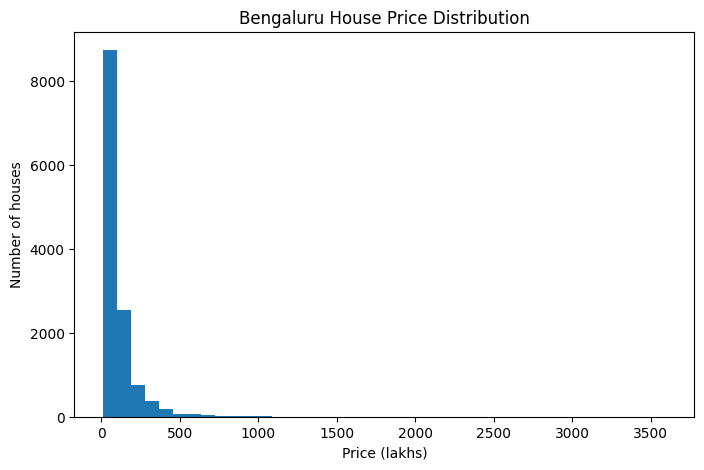

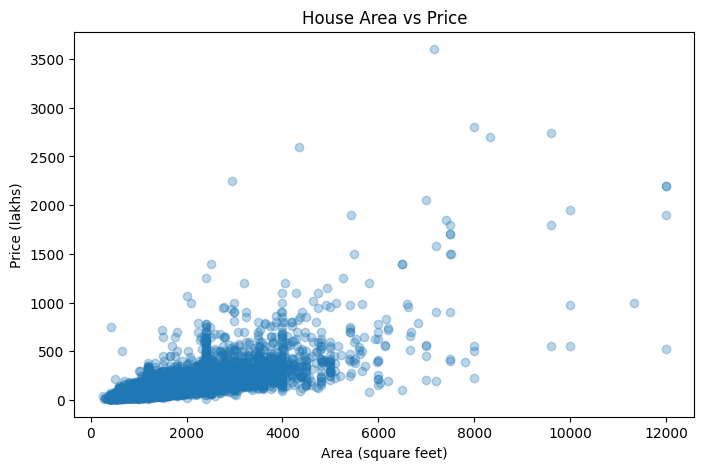

In [ ]:


plt.figure(figsize=(8, 5))
plt.hist(house["price"], bins=40)
plt.title("Bengaluru House Price Distribution")
plt.xlabel("Price (lakhs)")
plt.ylabel("Number of houses")
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(house["total_sqft"], house["price"], alpha=0.3)
plt.title("House Area vs Price")
plt.xlabel("Area (square feet)")
plt.ylabel("Price (lakhs)")
plt.show()


In [ ]:


feature_columns = [
    "area_type",
    "location",
    "total_sqft",
    "bath",
    "balcony",
    "bhk"
]

X = house[feature_columns]
y = house["price"]


In [ ]:


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))


Training rows: 10305
Testing rows: 2577


In [ ]:


categorical_columns = ["area_type", "location"]
numeric_columns = ["total_sqft", "bath", "balcony", "bhk"]

numeric_preparation = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_preparation = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numbers", numeric_preparation, numeric_columns),
    ("categories", categorical_preparation, categorical_columns)
])


In [ ]:


linear_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", LinearRegression())
])

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)


In [ ]:


linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print("Linear Regression")
print("MAE:", round(linear_mae, 2), "lakhs")
print("RMSE:", round(linear_rmse, 2), "lakhs")
print("R2:", round(linear_r2, 3))


Linear Regression
MAE: 38.01 lakhs
RMSE: 81.51 lakhs
R2: 0.564


In [ ]:


random_forest_model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("model", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        max_depth=20,
        min_samples_leaf=2,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

rf_predictions = random_forest_model.predict(X_test)


In [ ]:


rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest")
print("MAE:", round(rf_mae, 2), "lakhs")
print("RMSE:", round(rf_rmse, 2), "lakhs")
print("R2:", round(rf_r2, 3))


Random Forest
MAE: 31.56 lakhs
RMSE: 83.78 lakhs
R2: 0.539


In [ ]:


results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE (lakhs)": [linear_mae, rf_mae],
    "RMSE (lakhs)": [linear_rmse, rf_rmse],
    "R2": [linear_r2, rf_r2]
})

display(results)


,Model,MAE (lakhs),RMSE (lakhs),R2
0,Linear Regression,38.013347,81.505022,0.564137
1,Random Forest,31.556401,83.784392,0.539418


In [ ]:


if rf_mae < linear_mae:
    best_model = random_forest_model
    print("Selected model: Random Forest")
else:
    best_model = linear_model
    print("Selected model: Linear Regression")


Selected model: Random Forest


In [ ]:


new_house = pd.DataFrame([{
    "area_type": "Super built-up  Area",
    "location": "Whitefield",
    "total_sqft": 1200,
    "bath": 2,
    "balcony": 1,
    "bhk": 2
}])

predicted_price_lakhs = best_model.predict(new_house)[0]
predicted_price_rupees = predicted_price_lakhs * 100000

print("Predicted price:", round(predicted_price_lakhs, 2), "lakhs")
print("Predicted price: ₹", format(predicted_price_rupees, ",.0f"))


Predicted price: 59.17 lakhs
Predicted price: ₹ 5,916,952
